## Import Library

In [1]:
# 202431052_Anfal Ridho Hanif
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# 202431052_Anfal Ridho Hanif
data = pd.read_csv("drug200.csv")

In [3]:
# 202431052_Anfal Ridho Hanif
data.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,F,HIGH,HIGH,25.355,DrugY
1,47,M,LOW,HIGH,13.093,drugC
2,47,M,LOW,HIGH,10.114,drugC
3,28,F,NORMAL,HIGH,7.798,drugX
4,61,F,LOW,HIGH,18.043,DrugY


In [4]:
# 202431052_Anfal Ridho Hanif
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          200 non-null    int64  
 1   Sex          200 non-null    object 
 2   BP           200 non-null    object 
 3   Cholesterol  200 non-null    object 
 4   Na_to_K      200 non-null    float64
 5   Drug         200 non-null    object 
dtypes: float64(1), int64(1), object(4)
memory usage: 9.5+ KB


In [5]:
# 202431052_Anfal Ridho Hanif
data.describe()

,Age,Na_to_K
count,200.000000,200.000000
mean,44.315000,16.084485
std,16.544315,7.223956
min,15.000000,6.269000
25%,31.000000,10.445500
50%,45.000000,13.936500
75%,58.000000,19.380000
max,74.000000,38.247000


In [6]:
# Mengambil kolom numerikal
# 202431052_Anfal Ridho Hanif
numerical_features = [feature for feature in data.columns if data[feature].dtypes != 'O']
print("Jumlah fitur numerik = ", 
      len(numerical_features))
print("Daftar fitur numerik = ", 
      numerical_features)
display(data[numerical_features].head())

Jumlah fitur numerik =  2
Daftar fitur numerik =  ['Age', 'Na_to_K']


,Age,Na_to_K
0,23,25.355
1,47,13.093
2,47,10.114
3,28,7.798
4,61,18.043


In [7]:
#Mengambil kolom kategorikal
# 202431052_Anfal Ridho Hanif
categorical_features = [feature for feature in data.columns if data[feature].dtypes == 'O']
print("Jumlah fitur kategorikal = ", 
      len(categorical_features))
print("Daftar fitur kategorikal = ", 
      categorical_features)
display(data[categorical_features].head())

Jumlah fitur kategorikal =  4
Daftar fitur kategorikal =  ['Sex', 'BP', 'Cholesterol', 'Drug']


,Sex,BP,Cholesterol,Drug
0,F,HIGH,HIGH,DrugY
1,M,LOW,HIGH,drugC
2,M,LOW,HIGH,drugC
3,F,NORMAL,HIGH,drugX
4,F,LOW,HIGH,DrugY


In [8]:
# Menampilkan data unik pada fitur kategorikal
# 202431052_Anfal Ridho Hanif
for i in categorical_features:
    print(data[i].unique())

['F' 'M']
['HIGH' 'LOW' 'NORMAL']
['HIGH' 'NORMAL']
['DrugY' 'drugC' 'drugX' 'drugA' 'drugB']


In [9]:
# Mengubah kolom kategorikal menjadi angka untuk klasifikasi
# 202431052_Anfal Ridho Hanif
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
for feature in categorical_features:
    print(data[feature].unique())
    data[feature] = le.fit_transform(data[feature])
    print(data[feature].unique())

['F' 'M']
[0 1]
['HIGH' 'LOW' 'NORMAL']
[0 1 2]
['HIGH' 'NORMAL']
[0 1]
['DrugY' 'drugC' 'drugX' 'drugA' 'drugB']
[0 3 4 1 2]


In [10]:
data.head()

,Age,Sex,BP,Cholesterol,Na_to_K,Drug
0,23,0,0,0,25.355,0
1,47,1,1,0,13.093,3
2,47,1,1,0,10.114,3
3,28,0,2,0,7.798,4
4,61,0,1,0,18.043,0


In [11]:
# Mengambil kolom untuk fitur dan label
# 202431052_Anfal Ridho Hanif
x = data.drop(['Drug'], axis=1)
y = data['Drug']
print(x)
print(y)

     Age  Sex  BP  Cholesterol  Na_to_K
0     23    0   0            0   25.355
1     47    1   1            0   13.093
2     47    1   1            0   10.114
3     28    0   2            0    7.798
4     61    0   1            0   18.043
..   ...  ...  ..          ...      ...
195   56    0   1            0   11.567
196   16    1   1            0   12.006
197   52    1   2            0    9.894
198   23    1   2            1   14.020
199   40    0   1            1   11.349

[200 rows x 5 columns]
0      0
1      3
2      3
3      4
4      0
      ..
195    3
196    3
197    4
198    4
199    4
Name: Drug, Length: 200, dtype: int32


In [12]:
# Membagi Data Menjadi Data Test dan Data Train
# 202431052_Anfal Ridho Hanif
from sklearn.model_selection import train_test_split as tts

x_train, x_test, y_train, y_test = tts(x, y, test_size = 0.25, random_state = 0)

In [13]:
# Melatih model Gaussian Naive Bayes
# 202431052_Anfal Ridho Hanif
from sklearn.naive_bayes import GaussianNB

model = GaussianNB()
model.fit(x_train, y_train)

GaussianNB()

In [14]:
# 202431052_Anfal Ridho Hanif
y_pred_train = model.predict(x_train)
y_pred_test = model.predict(x_test)

Evaluasi Training
[[46 11  2  6  1]
 [ 0 18  0  0  0]
 [ 0  0 15  0  0]
 [ 0  0  0 13  0]
 [ 1  0  0  0 37]]
              precision    recall  f1-score   support

           0       0.98      0.70      0.81        66
           1       0.62      1.00      0.77        18
           2       0.88      1.00      0.94        15
           3       0.68      1.00      0.81        13
           4       0.97      0.97      0.97        38

    accuracy                           0.86       150
   macro avg       0.83      0.93      0.86       150
weighted avg       0.90      0.86      0.86       150



<function matplotlib.pyplot.show(close=None, block=None)>

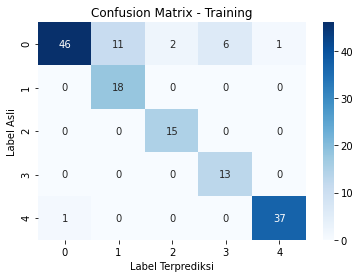

In [16]:
# 202431052_Anfal Ridho Hanif
from sklearn.metrics import confusion_matrix, classification_report

print("Evaluasi Training")
cm_train = confusion_matrix(y_train, y_pred_train)
print(cm_train)
print(classification_report(y_train, y_pred_train))

plt.figure(figsize=(6,4))
sns.heatmap(cm_train, annot = True, fmt='d', cmap = 'Blues', xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title("Confusion Matrix - Training")
plt.xlabel("Label Terprediksi")
plt.ylabel("Label Asli")
plt.show


Evaluasi Training
[[19  2  1  2  1]
 [ 0  5  0  0  0]
 [ 0  0  1  0  0]
 [ 0  0  0  3  0]
 [ 1  0  0  0 15]]
              precision    recall  f1-score   support

           0       0.95      0.76      0.84        25
           1       0.71      1.00      0.83         5
           2       0.50      1.00      0.67         1
           3       0.60      1.00      0.75         3
           4       0.94      0.94      0.94        16

    accuracy                           0.86        50
   macro avg       0.74      0.94      0.81        50
weighted avg       0.89      0.86      0.86        50



<function matplotlib.pyplot.show(close=None, block=None)>

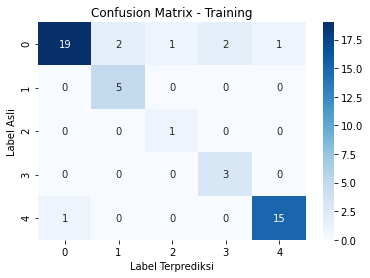

In [17]:
# Evaluasi Testing
# 202431052_Anfal Ridho Hanif

from sklearn.metrics import confusion_matrix, classification_report
print("Evaluasi Training")
cm_test = confusion_matrix(y_test, y_pred_test)
print(cm_test)
print(classification_report(y_test, y_pred_test))

plt.figure(figsize=(6,4))
sns.heatmap(cm_test, annot = True, fmt='d', cmap = 'Blues', xticklabels=np.unique(y), yticklabels=np.unique(y))
plt.title("Confusion Matrix - Training")
plt.xlabel("Label Terprediksi")
plt.ylabel("Label Asli")
plt.show